# GBM path simulation

Exact simulation of Black-Scholes paths with continuous dividend yield:

$S_{t+\Delta t} = S_t \exp\left((r - q - \sigma^2/2)\Delta t + \sigma\sqrt{\Delta t}\,Z\right)$

In [2]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.rng import LCG
from src.paths import simulate_gbm

In [3]:
# Model parameters (theoretical asset, standard textbook values)
S0, r, q, sigma, T = 100.0, 0.05, 0.02, 0.20, 1.0
n_steps, n_paths = 50, 20_000

In [4]:
rng = LCG(seed=42)
paths = simulate_gbm(S0, r, q, sigma, T, n_steps, n_paths, rng)

print("Shape            :", paths.shape)
print("First columb = S0:", np.all(paths[:, 0] == S0))
print("All prices >     :", np.all(paths >0))
print(f"Mean of S_T     : {paths[:, -1].mean():.3f}")

Shape            : (20000, 51)
First columb = S0: True
All prices >     : True
Mean of S_T     : 102.993


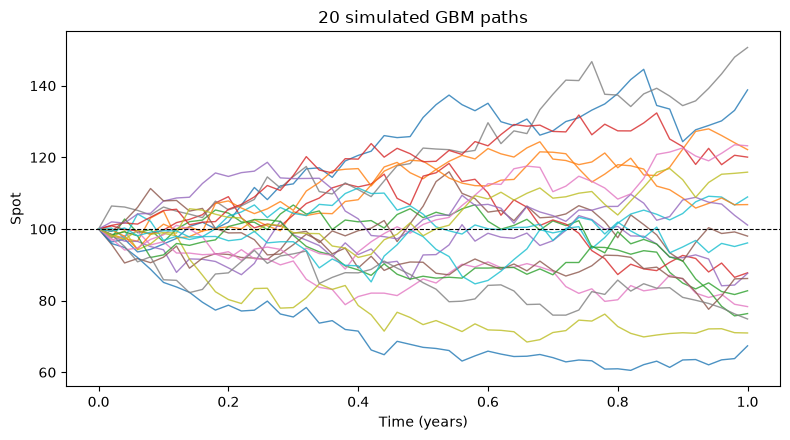

In [5]:
t = np.linspace(0, T, n_steps + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(t, paths[:20].T, lw=1, alpha=0.8)
plt.axhline(S0, color="black", linestyle="--", lw=0.8)
plt.title("20 simulated GBM paths")
plt.xlabel("Time (years)")
plt.ylabel("Spot")
plt.tight_layout()
plt.savefig("../figures/gbm_sample_paths.png", dpi=150)
plt.show()

## Validation against theory

Risk-neutral expectation, distribution of $\log S_T$ and discounted-martingale property.

In [6]:
ST = paths[:, -1]
theory = S0 * np.exp((r - q) * T)
mean = ST.mean()
se = ST.std(ddof=1) / np.sqrt(len(ST))

print(f"Theoretical E[S_T] : {theory:.4f}")
print(f"MC mean            : {mean:.4f} (std error {se:.4f})")
print(f"95% CI             : [{mean - 1.96*se:.4f}, {mean + 1.96*se:.4f}]")
print("Theory inside CI    :", mean - 1.96*se <= mean + 1.96*se)

Theoretical E[S_T] : 103.0455
MC mean            : 102.9931 (std error 0.1466)
95% CI             : [102.7058, 103.2804]
Theory inside CI    : True


In [7]:
from scipy.stats import kstest, norm, probplot

log_ret = np.log(ST / S0)
mu_th = (r - q - 0.5 * sigma**2) * T
sd_th = sigma * np.sqrt(T)

print(f"Mean of log-return : {log_ret.mean():.5f} (theory {mu_th:.5f})")
print(f"Std of log-return  : {log_ret.std():.5f} (theory {sd_th:.5f})")

stat, pvalue = kstest((log_ret - mu_th) / sd_th, "norm")
print(f"KS statistic : {stat:.5f} | p-value : {pvalue:.4f}")
print("Normality not rejected at 5%" if pvalue > 0.05 else "Normality rejected at 5%")

Mean of log-return : 0.00959 (theory 0.01000)
Std of log-return  : 0.19962 (theory 0.20000)
KS statistic : 0.00334 | p-value : 0.9786
Normality not rejected at 5%


Max |discounted mean - S0| : 0.1285


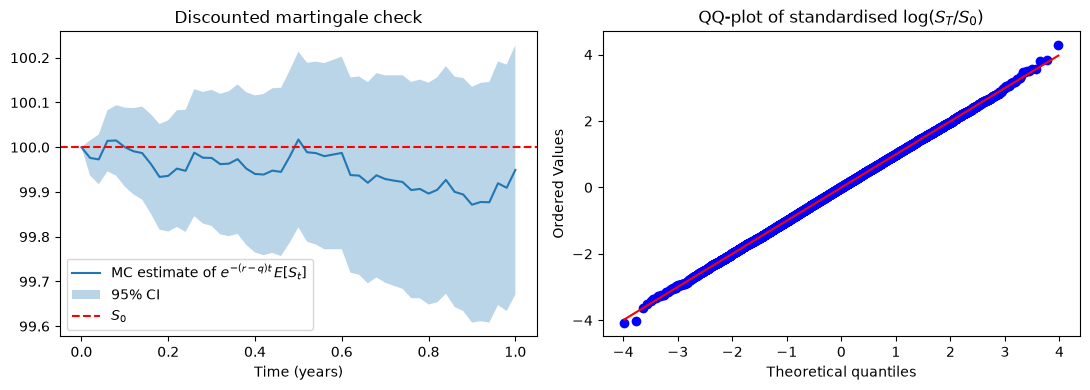

In [9]:
disc_mean = np.exp(-(r-q) * t) * paths.mean(axis=0)
disc_se = np.exp(-(r - q) * t) * paths.std(axis=0, ddof=1) / np.sqrt(paths.shape[0])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(t, disc_mean, label=r"MC estimate of $e^{-(r-q)t}\,E[S_t]$")
ax[0].fill_between(t, disc_mean - 1.96*disc_se, disc_mean + 1.96*disc_se, alpha=0.3, label="95% CI")
ax[0].axhline(S0, color="red", linestyle="--", label="$S_0$")
ax[0].set_title("Discounted martingale check")
ax[0].set_xlabel("Time (years)")
ax[0].legend()

probplot ((log_ret - mu_th) / sd_th, dist="norm", plot=ax[1])
ax[1].set_title(r"QQ-plot of standardised $\log(S_T/S_0)$")

plt.tight_layout()
plt.savefig("../figures/gbm_validation.png", dpi=150)

print(f"Max |discounted mean - S0| : {np.max(np.abs(disc_mean - S0)):.4f}")